In [25]:
include("flex.jl")
using MLDatasets

train_data = MLDatasets.FashionMNIST(split=:train)
test_data  = MLDatasets.FashionMNIST(split=:test)

function loader(data; batchsize::Int=1)
    x4dim = reshape(Float32.(data.features), 28, 28, 1, :)
    yhot  = onehotbatch(data.targets, 0:9)
    DataLoader((x4dim, yhot); batchsize, shuffle=true)
end

net = Chain(
  Conv((3, 3), 1 => 6, pad=1, bias=false),
  MaxPool((2, 2)),
  Conv((3, 3), 6 => 16, pad=1, bias=false),
  MaxPool((2, 2)),
  flatten,
  Dense(784 => 84, relu),
  Dropout(0.4),
  Dense(84 => 10),
)

Model(tensor, tensor, layer add with 2 arg(s), layer logit_ce with 2 arg(s), GraphNode[weight, weight, tensor, weight, layer conv with 2 arg(s), layer maxpool with 1 arg(s), weight, layer conv with 2 arg(s), layer maxpool with 1 arg(s), layer flatten with 1 arg(s), layer mul with 2 arg(s), weight, layer add with 2 arg(s), layer relu with 1 arg(s), layer dropout with 1 arg(s), layer mul with 2 arg(s), weight, layer add with 2 arg(s), tensor, layer logit_ce with 2 arg(s)], Base.RefValue{Bool}(true))

In [26]:
x1 = reshape(Float32.(test_data.features[:,:,1]), 28, 28, 1)
y1 = test_data.targets[1]
y1hat = net(x1)
@show hcat(onecold(y1hat, 0:9), y1)

using Statistics: mean
function loss_and_accuracy(model, data)
    model.training[] = false
    X = Float32.(data.features)
    Y = data.targets
    n = size(X, 3)
    total_loss = 0.0
    correct    = 0
    for i in 1:n
        xi   = reshape(X[:,:,i], 28, 28, 1)
        yi   = one_hot(Y[i])
        yhat = model(xi)
        total_loss += logitcrossentropy(yhat, yi)
        correct    += (onecold(yhat, 0:9) == Y[i])
    end
    model.training[] = true
    loss = total_loss / n
    acc  = round(100 * correct / n; digits=2)
    (; loss, acc, split=data.split)
end

@show loss_and_accuracy(net, test_data);

train_log = []
settings = (;
    eta       = 1e-2,
    epochs    = 3,
    batchsize = 10,
)

hcat(onecold(y1hat, 0:9), y1) = [4 9]
loss_and_accuracy(net, test_data) = (loss = 4.342507764351368, acc = 12.0, split = :test)


(eta = 0.01, epochs = 3, batchsize = 10)

In [27]:
opt = GradientDescent(settings.eta)
accuracy_log = zeros(settings.epochs, 2)
for epoch in 1:settings.epochs
    @time for (x_batch, y_batch) in loader(train_data, batchsize=settings.batchsize)
        for i in 1:size(x_batch, 4)
            zerograd!(net.graph)
            net.x_node.data .= x_batch[:,:,:,i]
            net.y_node.data .= y_batch[:,i]
            forward!(net.graph)
            backward!(net.graph)
            accumulate!(opt, net.graph)
        end
        optimize!(opt, net.graph)
    end

    loss, acc, _ = loss_and_accuracy(net, train_data)
    test_loss, test_acc, _ = loss_and_accuracy(net, test_data)
    println("epoch=$epoch  acc=$acc  test_acc=$test_acc")
    nt = (; epoch, loss, acc, test_loss, test_acc)
    push!(train_log, nt)
    accuracy_log[epoch, 1] = acc
    accuracy_log[epoch, 2] = test_acc
end

166.704431 seconds (1.98 G allocations: 110.393 GiB, 7.65% gc time, 1.34% compilation time)
epoch=1  acc=85.65  test_acc=84.82
167.978575 seconds (1.97 G allocations: 110.111 GiB, 7.14% gc time)
epoch=2  acc=86.7  test_acc=85.73
156.687058 seconds (1.97 G allocations: 110.112 GiB, 7.58% gc time)
epoch=3  acc=87.41  test_acc=86.37


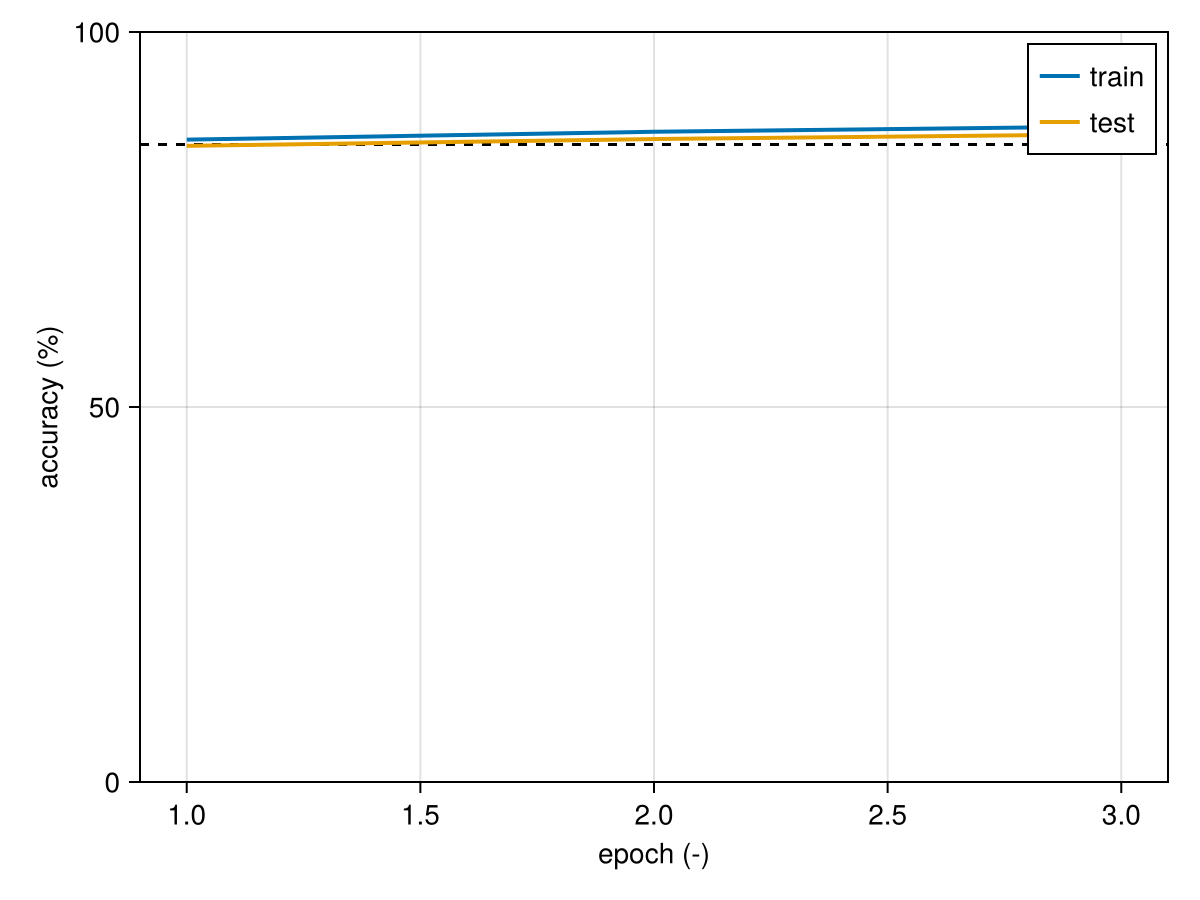

In [28]:
using CairoMakie
fig = Figure()
gca = Axis(fig[1,1], xlabel="epoch (-)", ylabel="accuracy (%)")
hlines!(gca, 85, linestyle=:dash, color=:black)
lines!(gca, accuracy_log[:,1], linewidth=2, label="train")
lines!(gca, accuracy_log[:,2], linewidth=2, label="test")
ylims!(gca, (0, 100))
axislegend(gca)
fig

In [29]:
net.training[] = false
x1 = reshape(Float32.(test_data.features[:,:,1]), 28, 28, 1)
y1 = test_data.targets[1]
y1hat = net(x1)
@show hcat(onecold(y1hat, 0:9), y1)
@show loss_and_accuracy(net, test_data);

hcat(onecold(y1hat, 0:9), y1) = [9 9]
loss_and_accuracy(net, test_data) = (loss = 0.37913286749124525, acc = 86.37, split = :test)


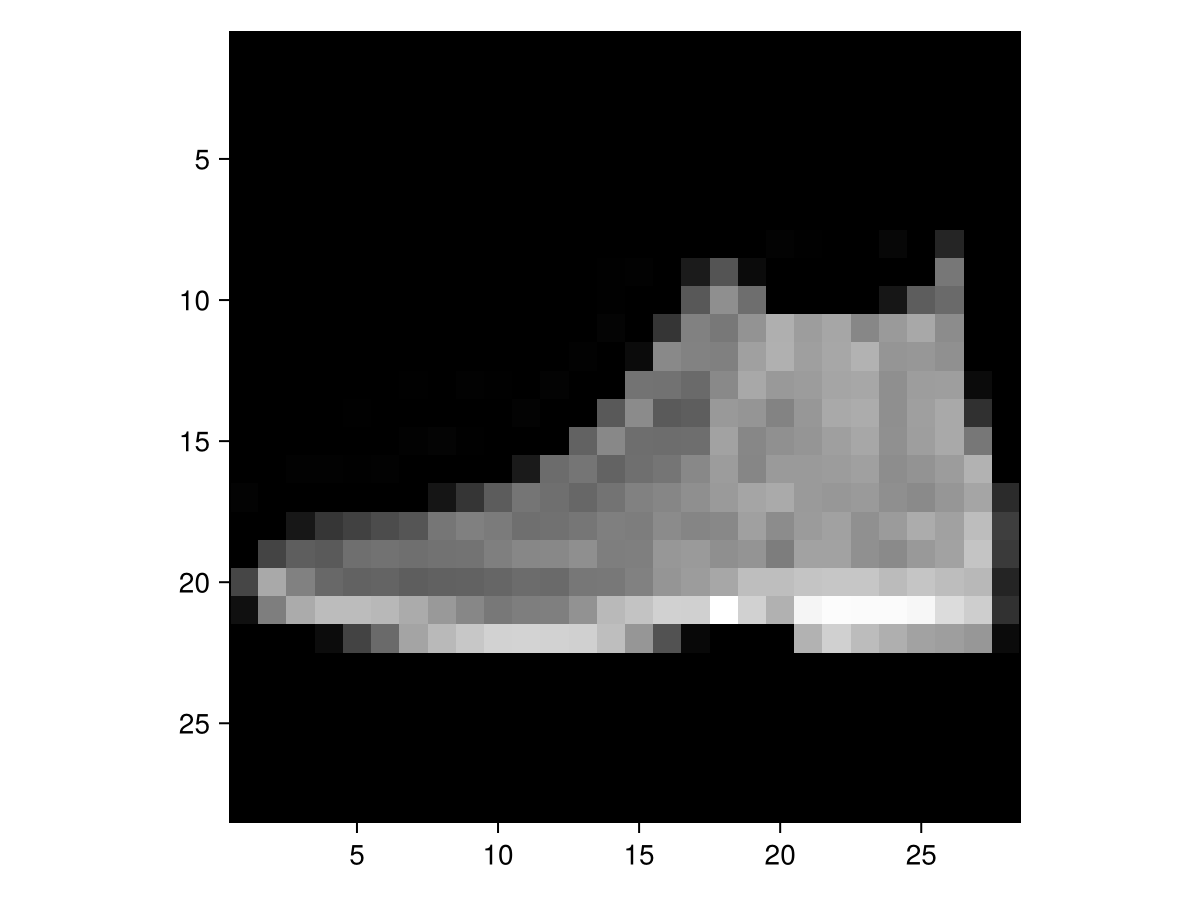

In [30]:
heatmap(test_data.features[:,:,1], colormap=:bone, axis=(aspect=DataAspect(), yreversed=true))